# Gross Code: Basic PPMs, Search Paths, and LER

In [1]:
from pathlib import Path
from dataclasses import asdict
import contextlib
import hashlib
import importlib.metadata as metadata
import io
import json
import os
import platform
import subprocess
import sys
import time

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lightstim").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import stim
from IPython.display import display, Markdown
from IPython.utils.capture import capture_output
import lightstim
from lightstim.protocols.bb_ppm import BBPPMExperiment, BBPPMStep
from lightstim.qec_code.BB_code.ppm.shift import build_tour_de_gross_code, logical_shift_tableaus
from lightstim.qec_code.BB_code.ppm.lowering import BBPPMCompiler
from lightstim.qec_code.BB_code.ppm.native_reporting import export_basic_measurements
from lightstim.qec_code.BB_code.ppm.reporting import (
    format_logical_pauli, export_shift_and_native_catalogs,
    export_rotation_catalog, export_plan_report,
)
from lightstim.noise.config import NoiseConfig
from lightstim.simulation.decoder_backend import SimulationPipeline, DecoderConfig
from lightstim.plot.config import PlotConfig
from lightstim.plot.plotter import plot_custom
from lightstim.plot.utils import add_error_bars

assert Path(lightstim.__file__).resolve().is_relative_to(ROOT)
# The server runner can redirect generated files to a persistent results disk.
OUTPUT = Path(os.environ.get("BB_PPM_OUTPUT_DIR",
    ROOT / "notebooks" / "LogicalOps" / "assets" / "bb_ppm")).expanduser().resolve()
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)

def display_path(path, *, base=OUTPUT):
    """Format printed paths relative to their stated base directory."""
    return Path(os.path.relpath(Path(path).resolve(), Path(base).resolve())).as_posix()


ROUNDS = 10  # syndrome-extraction rounds per basic LPU measurement
P_VALUES = (1e-4, 1e-3, 2e-3, 3e-3)
MAX_SHOTS, MAX_ERRORS, BATCH_SIZE = 50, 50, 50
NOISE_MODEL = "circuit_level_with_idling"
DECODER_NAME = "relay-bp"
# Paper-aligned gross-code Relay-BP settings in the installed 0.2.2 API.
# Tour de gross Table 7; Relay-BP paper Section IV / Figure 2.
DECODER_PARAMS = {
    "alpha": 1.0, "gamma0": 0.125,
    "pre_iter": 80, "num_sets": 600, "set_max_iter": 60,
    "gamma_dist_interval": (-0.24, 0.66), "stop_nconv": 5,
    "stopping_criterion": "nconv", "parallel": True,
}
REUSE_MATCHING_RESULTS = True  # reuse only identical circuits/settings/software

versions = {name: metadata.version(name) for name in
            ("stim", "numpy", "pandas", "relay-bp", "nbformat", "matplotlib")}
git_base = ["git", "--git-dir", str(ROOT / ".git"), "--work-tree", str(ROOT)]
git_env = dict(os.environ, GIT_OPTIONAL_LOCKS="0")
revision_result = subprocess.run(git_base + ["rev-parse", "HEAD"], cwd=ROOT,
    env=git_env, capture_output=True, text=True)
status_result = subprocess.run(git_base + ["status", "--porcelain"], cwd=ROOT,
    env=git_env, capture_output=True, text=True)
revision = revision_result.stdout.strip() if revision_result.returncode == 0 else None
git_dirty = bool(status_result.stdout.strip()) if status_result.returncode == 0 else None
runtime = {"commit": revision, "git_dirty": git_dirty,
           "python": platform.python_version(),
           "rayon_num_threads": os.environ.get("RAYON_NUM_THREADS", "automatic"), **versions}
print("LightStim:", display_path(lightstim.__file__, base=ROOT))
print("Output folder:", display_path(OUTPUT, base=ROOT))
print("Paths above are relative to the repository; artifact paths below are relative to Output folder.")
display(pd.Series(runtime, name="runtime"))


LightStim: lightstim/__init__.py
Output folder: ../bb_ppm_results
Paths above are relative to the repository; artifact paths below are relative to Output folder.


commit               493e06ccf74522ba5cfbda6040e881f27ba79d0e
git_dirty                                               False
python                                                3.12.15
rayon_num_threads                                          64
stim                                                   1.16.0
numpy                                                   2.2.6
pandas                                                  3.1.1
relay-bp                                                0.2.2
nbformat                                               5.11.1
matplotlib                                             3.11.2
Name: runtime, dtype: object

**Cell 1 · 15 Basic LPU Measurements and Stabilizer Definitions**

In [2]:
basic_rows = export_basic_measurements(OUTPUT / "basic_measurements", validate=True)
assert len(basic_rows) == 15
display(pd.DataFrame(basic_rows)[[
    "target", "lpu_mode", "vertex_checks", "cycle_checks", "edge_qubits",
    "modified_bb_checks", "validation_status",
]])
print("All 15 stabilizer definitions:", display_path(OUTPUT / "basic_measurements"))
print("All 15 measurement summaries:", display_path(OUTPUT / "basic_measurements" / "manifest.json"))


,target,lpu_mode,vertex_checks,cycle_checks,edge_qubits,modified_bb_checks,validation_status
0,X7,right,12,3,18,18,passed
1,Y7,full,23,19,47,36,passed
2,Z7,left,12,5,18,18,passed
3,X1,left,12,5,18,18,passed
4,X1 X7,full,23,19,47,36,passed
5,X1 Y7,full,23,19,47,54,passed
6,X1 Z7,left,12,5,18,36,passed
7,Y1,full,23,19,47,36,passed
8,Y1 X7,full,23,19,47,54,passed
9,Y1 Y7,full,23,19,47,72,passed


All 15 stabilizer definitions: basic_measurements
All 15 measurement summaries: basic_measurements/manifest.json


**Cell 2 · 36 Logical Shifts and 540 Native Measurements**

In [3]:
from IPython.display import HTML

gross = build_tour_de_gross_code()
compiler = BBPPMCompiler(logical_shift_tableaus(gross))
catalogs = export_shift_and_native_catalogs(compiler, gross, OUTPUT)
shift_rows = catalogs["rows"]["shifts"]
native_rows = catalogs["rows"]["native_measurements"]
assert len(shift_rows) == 36 and len(native_rows) == 540
display(pd.DataFrame(shift_rows)[[
    "shift", "inverse_shift",
]])
native_table = pd.DataFrame(native_rows)
# Preview genuinely shifted entries; catalogue ordering is by Pauli string.
shifted_preview = native_table[(native_table["shift_x"] != 0) | (native_table["shift_y"] != 0)].head(10)
display(Markdown(f"Showing {len(shifted_preview)} examples out of {len(native_rows)} native measurements."))
display(HTML(shifted_preview[[
    "basic_measurement", "shift", "conjugated_pauli", "chronology",
]].rename(columns={
    "basic_measurement": "before shift",
    "conjugated_pauli": "after shift",
}).to_html(index=False)))
print("Distinct shifts:", len(shift_rows))
print("Native measurements:", len(native_rows))
for name, path in catalogs["paths"].items():
    print(f"{name}: {display_path(path)}")


,shift,inverse_shift
0,"x: 0, y: 0","x: 0, y: 0"
1,"x: 0, y: 1","x: 0, y: 5"
2,"x: 0, y: 2","x: 0, y: 4"
3,"x: 0, y: 3","x: 0, y: 3"
4,"x: 0, y: 4","x: 0, y: 2"
5,"x: 0, y: 5","x: 0, y: 1"
6,"x: 1, y: 0","x: 5, y: 0"
7,"x: 1, y: 1","x: 5, y: 5"
8,"x: 1, y: 2","x: 5, y: 4"
9,"x: 1, y: 3","x: 5, y: 3"


Showing 10 examples out of 540 native measurements.

before shift,shift,after shift,chronology
+X7,"x: 3, y: 5",+X12,"x: 3, y: 1 -> Measure(+X7) -> x: 3, y: 5"
+Z7,"x: 2, y: 4",+Z12,"x: 4, y: 2 -> Measure(+Z7) -> x: 2, y: 4"
+X7,"x: 5, y: 5",+X11,"x: 1, y: 1 -> Measure(+X7) -> x: 5, y: 5"
+X7,"x: 1, y: 5",+X11 X12,"x: 5, y: 1 -> Measure(+X7) -> x: 1, y: 5"
+Z7,"x: 1, y: 2",+Z11,"x: 5, y: 4 -> Measure(+Z7) -> x: 1, y: 2"
+X7,"x: 4, y: 1",+X10,"x: 2, y: 5 -> Measure(+X7) -> x: 4, y: 1"
+X7,"x: 4, y: 0",+X10 X11 X12,"x: 2, y: 0 -> Measure(+X7) -> x: 4, y: 0"
+Z7,"x: 2, y: 5",+Z10,"x: 4, y: 1 -> Measure(+Z7) -> x: 2, y: 5"
+Z7,"x: 5, y: 0",+Z10 Z12,"x: 1, y: 0 -> Measure(+Z7) -> x: 5, y: 0"
+Z7,"x: 0, y: 2",+Z10 Z11,"x: 0, y: 4 -> Measure(+Z7) -> x: 0, y: 2"


Distinct shifts: 36
Native measurements: 540
shifts_json: shifts/shifts.json
shifts_csv: shifts/shifts.csv
native_json: native_measurements/native_measurements.json
native_csv: native_measurements/native_measurements.csv


**Cell 3 · 245 Implementable Nontrivial Rotation Axes $A$**

In [4]:
rotation_catalog = export_rotation_catalog(compiler, OUTPUT)
axis_rows = rotation_catalog["rows"]["axes"]
implementation_rows = rotation_catalog["rows"]["implementations"]
assert len(axis_rows) == 245 and len(implementation_rows) == 253
axis_preview = pd.DataFrame(axis_rows).head(10)
display(Markdown(f"Showing {len(axis_preview)} examples out of {len(axis_rows)} distinct available rotation axes A."))
display(HTML(axis_preview[[
    "axis", "implementation_count", "chosen_joint",
    "chosen_shift", "chosen_basic", "prepare", "readout", "forward_correction",
]].rename(columns={
    "axis": "axis (A)", "chosen_joint": "chosen_joint (Q₁A)",
}).to_html(index=False)))
print("Nontrivial Q1 A implementations:", len(implementation_rows))
print("Distinct nontrivial data rotation axes A:", len(axis_rows))
for name, path in rotation_catalog["paths"].items():
    print(f"{name}: {display_path(path)}")


Showing 10 examples out of 245 distinct available rotation axes A.

axis (A),implementation_count,chosen_joint (Q₁A),chosen_shift,chosen_basic,prepare,readout,forward_correction
+X7,3,+X1 X7,"x: 0, y: 0",+X1 X7,Z1,Y1,r*m*s = +1: apply/track A
+Y7,3,+X1 Y7,"x: 0, y: 0",+X1 Y7,Z1,Y1,r*m*s = +1: apply/track A
+Z7,3,+X1 Z7,"x: 0, y: 0",+X1 Z7,Z1,Y1,r*m*s = +1: apply/track A
+Z6,1,+Z1 Z6,"x: 0, y: 5",+Z1,Y1,X1,r*m*s = +1: apply/track A
+Z6 X8 X11,1,+Z1 Z6 X8 X11,"x: 0, y: 5",+Z1 X7,Y1,X1,r*m*s = +1: apply/track A
+Z6 Z7 Y8 X11,1,+Z1 Z6 Z7 Y8 X11,"x: 0, y: 5",+Z1 Y7,Y1,X1,r*m*s = +1: apply/track A
+Z6 Z7 Z8,1,+Z1 Z6 Z7 Z8,"x: 0, y: 5",+Z1 Z7,Y1,X1,r*m*s = +1: apply/track A
+X4 X6,1,+X1 X4 X6,"x: 5, y: 3",+X1,Z1,Y1,r*m*s = +1: apply/track A
+X4 X6 X7 X8 X10,1,+X1 X4 X6 X7 X8 X10,"x: 5, y: 3",+X1 X7,Z1,Y1,r*m*s = +1: apply/track A
+X4 X6 Y7 X8 Z9 X10 Z11,1,+X1 X4 X6 Y7 X8 Z9 X10 Z11,"x: 5, y: 3",+X1 Y7,Z1,Y1,r*m*s = +1: apply/track A


Nontrivial Q1 A implementations: 253
Distinct nontrivial data rotation axes A: 245
axes_json: rotation_axes/rotation_axes.json
axes_csv: rotation_axes/rotation_axes.csv
implementations_json: rotation_axes/rotation_implementations.json
implementations_csv: rotation_axes/rotation_implementations.csv


**Cell 4 · Bidirectional Search, Selected Path, and Full Operation Sequence**

Round 0 initializes the search. Each subsequent round expands the side with the smaller frontier. New, total, and frontier counts refer to distinct Pauli operators.

**PPM 0 — target: +X2 Z7 X12**

Search round,Expanded side,Target new,Target total,Target frontier,Native new,Native total,Native frontier,Connected,Meeting point
0,Initialization,1,1,1,245,245,245,No,—
1,target,100,101,100,0,245,245,Yes,+Y7


,step,rotation,before,axis,direction,after
0,0,0,+X2 Z7 X12,+X2 X7 X12,1,+Y7


The target PPM is expanded in execution order: forward rotations → central measurement → inverse rotations. Braces on the right mark each stage.

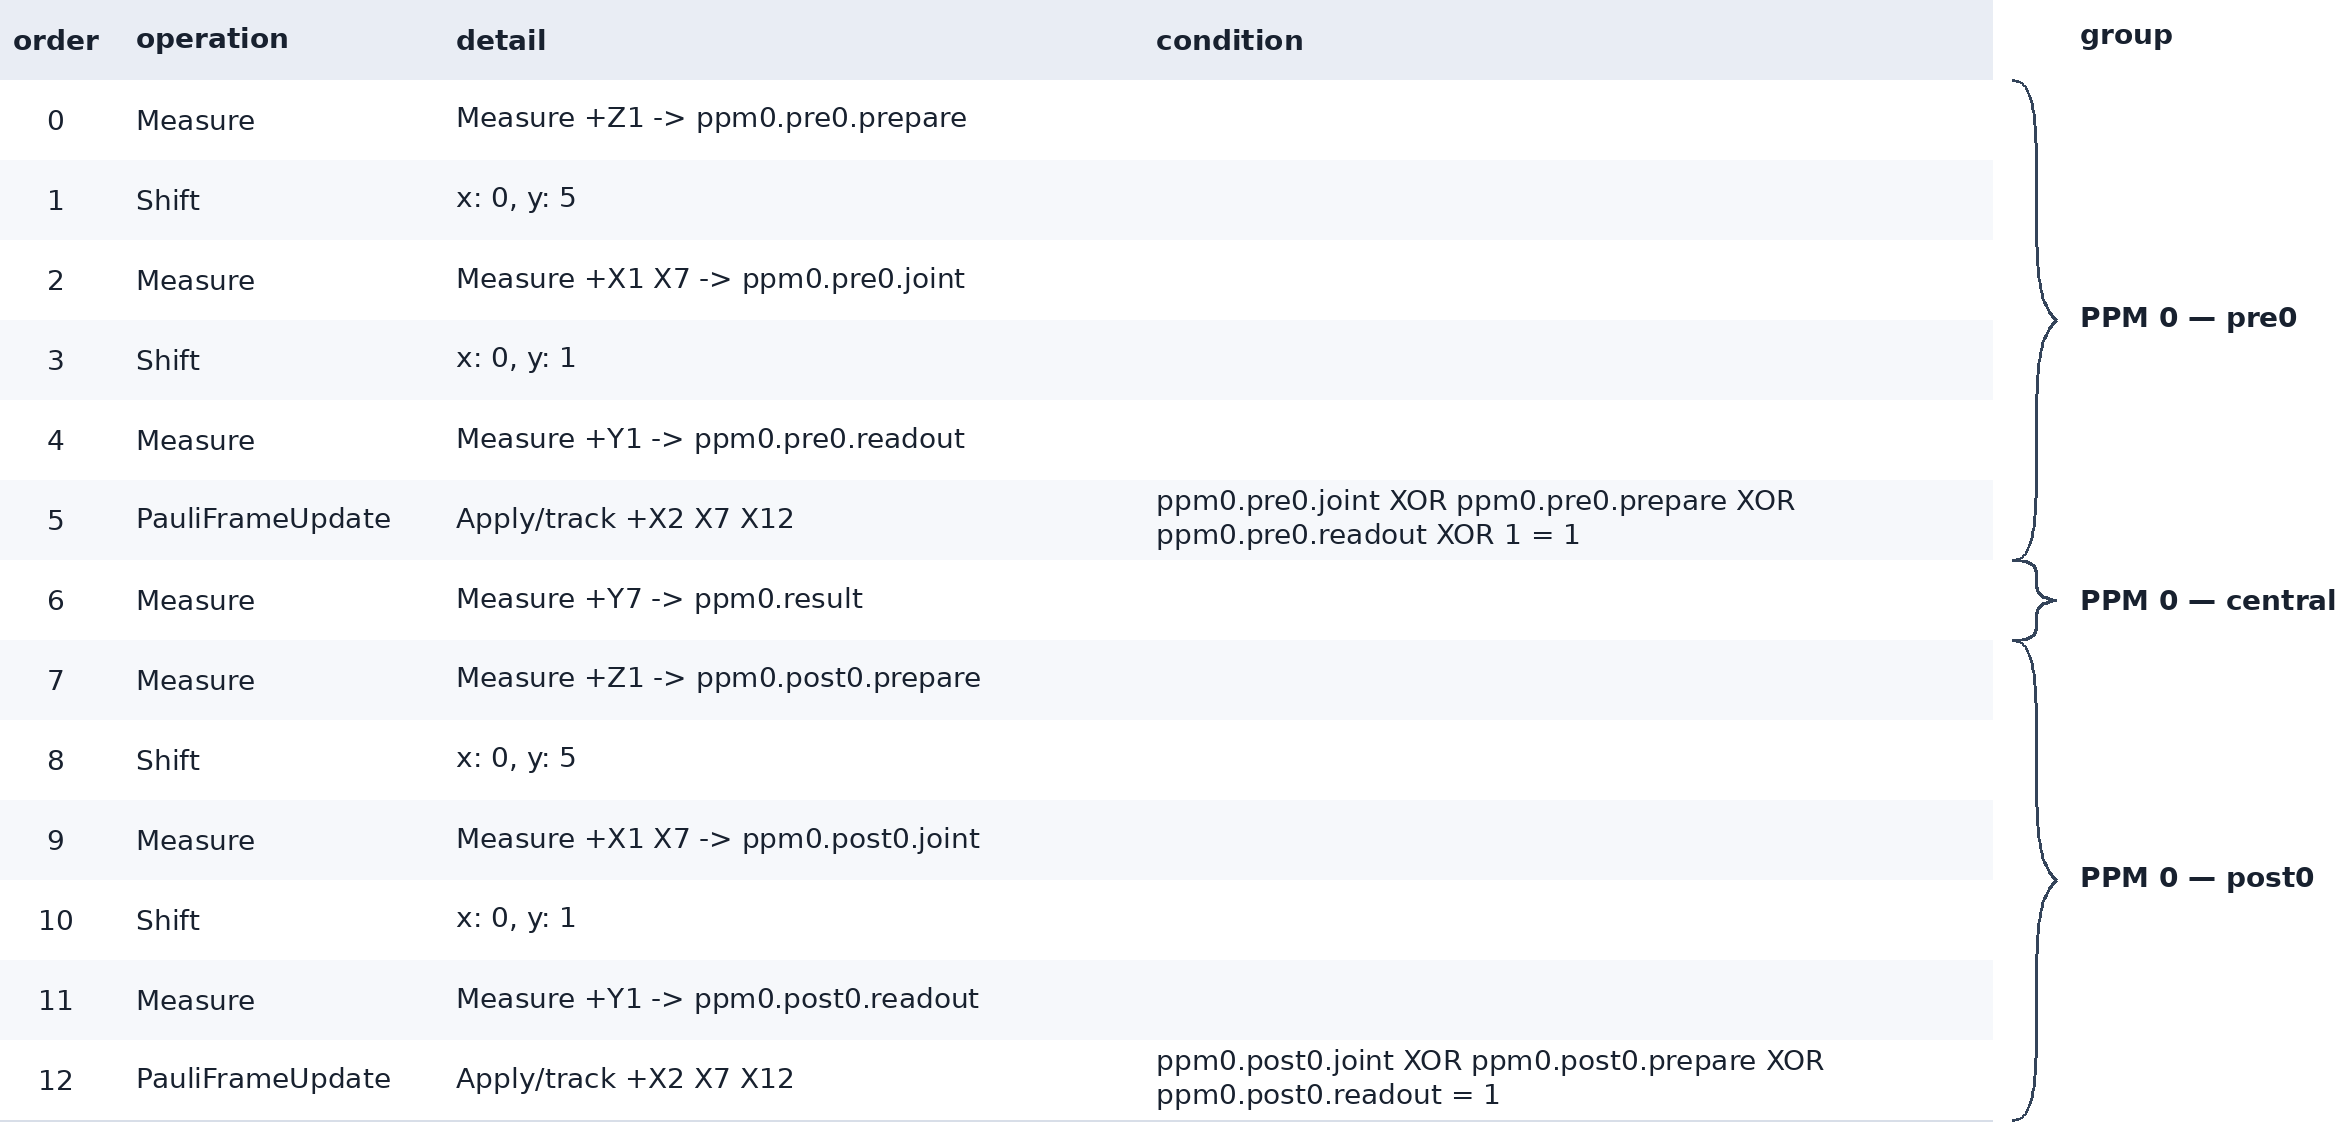

,step,measurements,shifts,frame_updates,output
0,0,7,4,2,ppm0.result


Compiled-plan SHA256: f028b3134db48c3f0f7a6c5b9ae97ddcd7c95cffcb59f8cfc0afc28ad1679a37
plans_json: searches/plans.json
summary_csv: searches/plan_summary.csv
search_csv: searches/search_progress.csv
path_csv: searches/selected_paths.csv
operations_csv: searches/operations.csv


In [5]:
ppm_sequence = [BBPPMStep(((2, "X"), (7, "Z"), (12, "X")))]
# Advanced input example:
# ppm_sequence = [BBPPMStep(((2, "X"), (8, "X"), (9, "X")))]

plans = tuple(compiler.compile(step.targets, prefix=f"ppm{i}")
              for i, step in enumerate(ppm_sequence))
plan_report = export_plan_report(compiler, plans, OUTPUT)
from IPython.display import HTML

display(Markdown("Round 0 initializes the search. Each subsequent round expands the side with the smaller frontier. New, total, and frontier counts refer to distinct Pauli operators."))
for step, plan in enumerate(plans):
    display(Markdown(f"**PPM {step} — target: {format_logical_pauli(plan.target)}**"))
    if plan.search_status == "cached":
        display(Markdown("This target reuses a cached path. The records below are from its original search; no new expansion was performed."))
    search_rows = [row for row in plan_report["rows"]["search"] if row["step"] == step]
    if search_rows:
        search_table = pd.DataFrame(search_rows)[[
            "round", "expanded_side", "target_new", "target_total", "target_frontier",
            "native_new", "native_total", "native_frontier", "connected", "meeting_pauli",
        ]].copy()
        search_table["expanded_side"] = search_table["expanded_side"].map({
            "initial": "Initialization", "target": "target", "native": "native"})
        search_table["connected"] = search_table["connected"].map({True: "Yes", False: "No"})
        search_table["meeting_pauli"] = search_table["meeting_pauli"].fillna("—")
        search_table = search_table.rename(columns={
            "round": "Search round", "expanded_side": "Expanded side",
            "target_new": "Target new", "target_total": "Target total",
            "target_frontier": "Target frontier", "native_new": "Native new",
            "native_total": "Native total", "native_frontier": "Native frontier",
            "connected": "Connected", "meeting_pauli": "Meeting point",
        })
        display(HTML(search_table.to_html(index=False)))
    else:
        display(Markdown("This target requires no bidirectional search; the measurement plan is generated directly."))
path_table = pd.DataFrame(plan_report["rows"]["path"])
if len(path_table):
    display(path_table[["step", "rotation", "before", "axis", "direction", "after"]])
else:
    print("This target needs no Clifford search path.")

from base64 import b64encode
from IPython.display import Image
from lightstim.qec_code.BB_code.ppm.reporting import (
    render_operation_table_png, operation_table_plain_text,
)
display(Markdown("The target PPM is expanded in execution order: forward rotations → central measurement → inverse rotations. Braces on the right mark each stage."))
# Fixed geometry is embedded as PNG so GitHub cannot reflow rows or braces.
operation_rows = plan_report["rows"]["operations"]
operation_png = render_operation_table_png(operation_rows, row_height=40, scale=2)
operation_image = Image(data=operation_png, format="png", retina=True)
display({
    "image/png": b64encode(operation_png).decode("ascii"),
    "text/plain": operation_table_plain_text(operation_rows),
}, raw=True, metadata={"image/png": {
    "width": operation_image.width, "height": operation_image.height,
}})
display(pd.DataFrame(plan_report["rows"]["summary"])[[
    "step", "measurements", "shifts", "frame_updates", "output",
]])
# Search diagnostics do not change the executable measurement plan.
executable_plans = [
    {key: value for key, value in asdict(plan).items()
     if key not in ("search_trace", "search_status")}
    for plan in plans
]
plan_payload = json.dumps(executable_plans, sort_keys=True)
plan_sha256 = hashlib.sha256(plan_payload.encode()).hexdigest()
print("Compiled-plan SHA256:", plan_sha256)
for name, path in plan_report["paths"].items():
    print(f"{name}: {display_path(path)}")


**Cell 5 · Run Cell 4 Plans to Estimate LER for the Same PPM Sequence**

sequence                                                                      X2 Z7 X12
plan_objects_reused                                                                True
physical_qubits                                                                     378
ticks                                                                              1115
detectors                                                                         15510
observables                                                                          10
build_seconds                                                                 29.231251
p0_silent                                                                          True
plan_sha256            f028b3134db48c3f0f7a6c5b9ae97ddcd7c95cffcb59f8cfc0afc28ad1679a37
circuit_sha256         12ebce837acec62f66c7c07d513d28f7fb293ba2dea6ee819869be9402aebc87
commit                                         493e06ccf74522ba5cfbda6040e881f27ba79d0e
git_dirty                       

Example raw PPM bits (0 -> +1, 1 -> -1; neither value alone means failure): [0 1 1 0 1 0 0 1 0 0 1 0 0 0 1 0]


p=0.0001: sampling and decoding ...


Task 1/1: {'p': 0.0001, 'sequence': 'X2 Z7 X12', 'plan_sha256': 'f028b3134db48c3f0f7a6c5b9ae97ddcd7c95cffcb59f8cfc0afc28ad1679a37', 'run_id': 'cdfeaea848f9e433', 'max_shots': 50, 'max_errors': 50}


shots=50 kept=50 errors=0 LER=0.00e+00±-- elapsed=292.3s ETA=0s


final shots=50 kept=50 errors=0 LER=0.00e+00±-- elapsed=292.3s ETA=0s


p=0.0001: 0/50 failures, LER=0


p=0.001: reuse matching sampled result from run 57d014f2cc436091: 12/50 failures


p=0.002: reuse matching sampled result from run 57d014f2cc436091: 32/50 failures


p=0.003: reuse matching sampled result from run 57d014f2cc436091: 50/50 failures


,sequence,p,shots,errors,logical_error_rate,logical_error_rate_err,seconds
0,X2 Z7 X12,0.0001,50,0,0.00,0.000003,292.338129
1,X2 Z7 X12,0.0010,50,12,0.24,0.118381,3828.781094
2,X2 Z7 X12,0.0020,50,32,0.64,0.133049,3434.345229
3,X2 Z7 X12,0.0030,50,50,1.00,0.000003,3652.391410


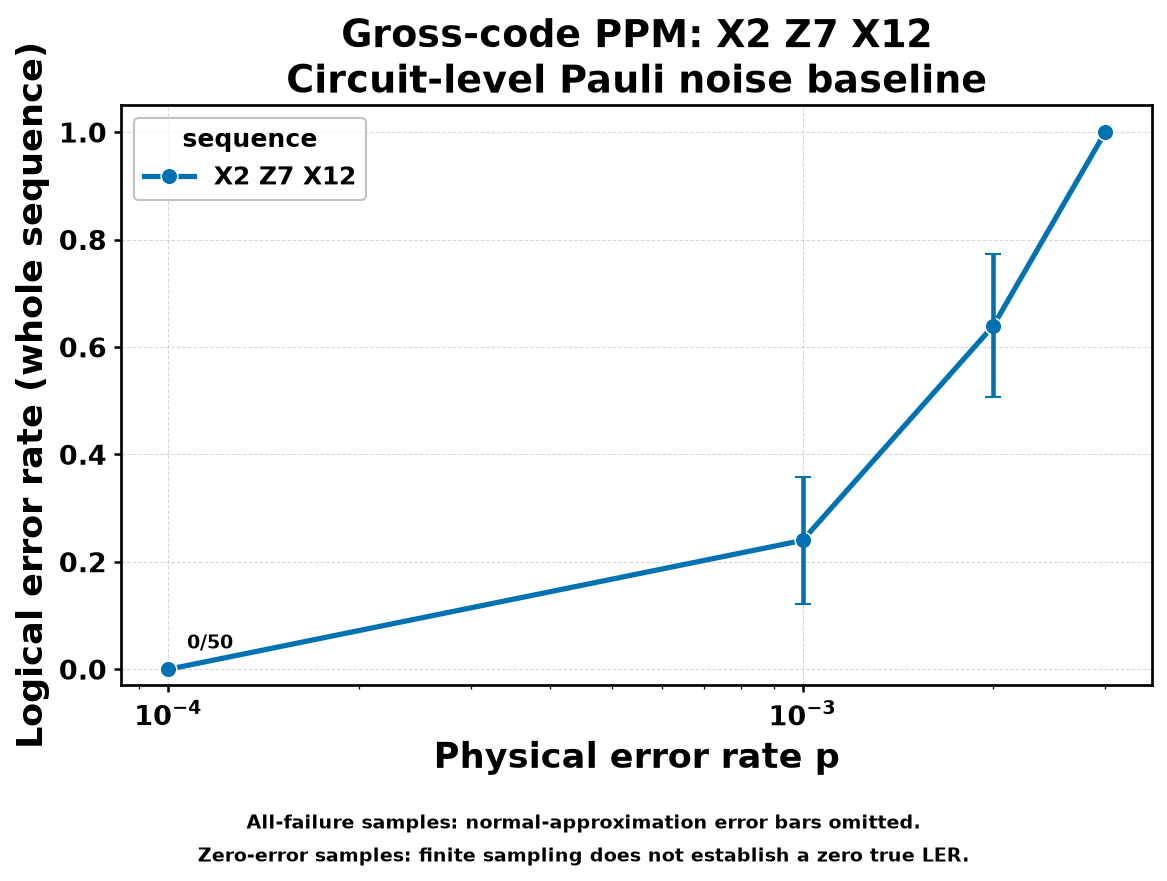

Zero-error points are plotted at 0; finite sampling does not establish a zero true LER.
Sampled results: ler/cdfeaea848f9e433/results.csv
LER figure: ler/cdfeaea848f9e433/ler.png
Configuration and physical circuits: ler/cdfeaea848f9e433


In [6]:
experiment = BBPPMExperiment(
    gross, ppm_sequence, plans=plans,
    initial_states="X", final_measure_states="X", rounds=ROUNDS,
    rounds_init=1, rounds_final=1, noiseless_boundaries=True,
    noise_model=NOISE_MODEL,
)
assert len(experiment.plans) == len(plans)
assert all(actual is planned for actual, planned in zip(experiment.plans, plans))
started = time.perf_counter()
with capture_output():
    clean = experiment.build()
build_seconds = time.perf_counter() - started
dets, observables = clean.compile_detector_sampler(seed=7).sample(64, separate_observables=True)
assert clean.num_observables > 0 and not dets.any() and not observables.any()
clean.detector_error_model()  # also verifies deterministic detector/observable definitions
circuit_sha256 = hashlib.sha256(str(clean).encode()).hexdigest()
sequence_label = "; ".join(format_logical_pauli(plan.target).lstrip("+") for plan in plans)

source_files = [
    "lightstim/protocols/bb_ppm.py", "lightstim/qec_code/BB_code/ppm/lowering.py",
    "lightstim/qec_code/BB_code/ppm/native.py", "lightstim/qec_code/BB_code/ppm/shift.py",
]
source_hashes = {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
                 for name in source_files}
run_config = {
    "sequence": sequence_label, "targets": [list(step.targets) for step in ppm_sequence],
    "plan_sha256": plan_sha256, "circuit_sha256": circuit_sha256,
    "code": "gross", "logical_basis": "tour_de_gross", "rounds": ROUNDS,
    "initial_states": "X", "final_measure_states": "X", "rounds_init": 1, "rounds_final": 1,
    "noiseless_boundaries": True, "noise_model": NOISE_MODEL,
    "noise_parameters": "p_1q=p_2q=p_meas=p_reset=p_idle=p", "p_values": list(P_VALUES),
    "decoder": DECODER_NAME, "decoder_params": DECODER_PARAMS,
    "max_shots": MAX_SHOTS, "max_errors": MAX_ERRORS, "batch_size": BATCH_SIZE,
    "num_workers": 1, "sampler_seed": 0, "versions": versions,
    "source_sha256": source_hashes, "error_bars": "LightStim 95% normal approximation",
}
run_id = hashlib.sha256(json.dumps(run_config, sort_keys=True).encode()).hexdigest()[:16]
ler_folder = OUTPUT / "ler" / run_id
ler_folder.mkdir(parents=True, exist_ok=True)
config_path, results_path = ler_folder / "configuration.json", ler_folder / "results.csv"
if config_path.exists():
    assert json.loads(config_path.read_text(encoding="utf-8")) == json.loads(json.dumps(run_config))
config_path.write_text(json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8")
(ler_folder / "clean.stim").write_text(str(clean), encoding="utf-8")
resources = {"sequence": sequence_label, "plan_objects_reused": True,
    "physical_qubits": clean.num_qubits, "ticks": clean.num_ticks,
    "detectors": clean.num_detectors, "observables": clean.num_observables,
    "build_seconds": build_seconds, "p0_silent": True,
    "plan_sha256": plan_sha256, "circuit_sha256": circuit_sha256, **runtime}
(ler_folder / "resources.json").write_text(json.dumps(resources, indent=2), encoding="utf-8")
display(pd.Series(resources, name="physical experiment"))
raw = clean.compile_sampler(seed=11).sample(16)
print("Example raw PPM bits (0 -> +1, 1 -> -1; neither value alone means failure):",
      experiment.ppm_outcomes[0].evaluate(raw).astype(int))

all_results = pd.read_csv(results_path) if REUSE_MATCHING_RESULTS and results_path.exists() else pd.DataFrame()
completed_p = set(all_results["p"]) if len(all_results) else set()
pipeline = SimulationPipeline(
    DecoderConfig(DECODER_NAME, params=DECODER_PARAMS),
    max_shots=MAX_SHOTS, max_errors=MAX_ERRORS, batch_size=BATCH_SIZE,
    num_workers=1, print_progress=True,
    progress_min_delta_shots=BATCH_SIZE, progress_interval_sec=60,
    progress_output="logging", progress_file_path=str(ler_folder / "progress.log"),
)
for p in P_VALUES:
    if p in completed_p:
        saved = all_results.loc[all_results["p"] == p].iloc[0]
        print(f"p={p:g}: reuse matching sampled result from run {saved['run_id']}: "
              f"{int(saved['errors'])}/{int(saved['shots'])} failures", flush=True)
        continue
    noise = NoiseConfig(p_1q=p, p_2q=p, p_meas=p, p_reset=p, p_idle=p)
    noisy = experiment.builder.build_noisy_circuit(noise, NOISE_MODEL, circuit=clean)
    (ler_folder / f"noisy_p_{p:g}.stim").write_text(str(noisy), encoding="utf-8")
    print(f"p={p:g}: sampling and decoding ...", flush=True)
    point = pipeline.run_batch([(noisy, {
        "p": p, "sequence": sequence_label, "plan_sha256": plan_sha256,
        "run_id": run_id, "max_shots": MAX_SHOTS, "max_errors": MAX_ERRORS,
    })])
    all_results = pd.concat([all_results, point], ignore_index=True)
    checkpoint_path = results_path.with_suffix(".csv.tmp")
    all_results.to_csv(checkpoint_path, index=False)
    checkpoint_path.replace(results_path)  # publish each completed point atomically
    record = point.iloc[0]
    print(f"p={p:g}: {int(record['errors'])}/{int(record['shots'])} failures, "
          f"LER={record['logical_error_rate']:.5g}", flush=True)

all_results = all_results.sort_values("p").reset_index(drop=True)
# Recompute derived error bars after joining saved and newly sampled rows.
plot_data = add_error_bars(all_results.drop(columns=["logical_error_rate_err"], errors="ignore"))
checkpoint_path = results_path.with_suffix(".csv.tmp")
plot_data.to_csv(checkpoint_path, index=False)
checkpoint_path.replace(results_path)
display(plot_data[["sequence", "p", "shots", "errors", "logical_error_rate",
                   "logical_error_rate_err", "seconds"]])
# Replace Cell 11 from `positive = ...` through the zero-error print below.
# This display-only block preserves actual estimates and existing error bars.
with capture_output():
    fig = plot_custom(plot_data, PlotConfig(
        x="p", y="logical_error_rate", hue="sequence",
        palette={sequence_label: "#0072B2"},
        x_label="Physical error rate p", y_label="Logical error rate (whole sequence)",
        title="Gross-code PPM: " + sequence_label + "\nCircuit-level Pauli noise baseline",
        figsize=(8, 5.5), y_scale="linear",
    ))
ax = fig.axes[0]
interior = plot_data[(plot_data["errors"] > 0) &
                     (plot_data["errors"] < plot_data["shots"])]
ax.errorbar(interior["p"], interior["logical_error_rate"],
    yerr=interior["logical_error_rate_err"], fmt="none", color="#0072B2", capsize=4)
# Small padding below zero keeps the complete marker visible at its true value.
ax.set_ylim(-0.03, 1.05)
zero_error = plot_data[plot_data["errors"] == 0]
for _, record in zero_error.iterrows():
    ax.annotate(f"0/{int(record['shots'])}",
                xy=(record["p"], record["logical_error_rate"]),
                xytext=(9, 10), textcoords="offset points", fontsize=9)
footnotes = []
if (plot_data["errors"] == plot_data["shots"]).any():
    footnotes.append("All-failure samples: normal-approximation error bars omitted.")
if len(zero_error):
    footnotes.append("Zero-error samples: finite sampling does not establish a zero true LER.")
for index, note in enumerate(footnotes):
    fig.text(0.5, -0.025 - 0.04 * index, note, ha="center", fontsize=9)
fig.savefig(ler_folder / "ler.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)
if len(zero_error):
    print("Zero-error points are plotted at 0; finite sampling does not establish a zero true LER.")

(OUTPUT / "ler" / "latest.json").write_text(json.dumps({"run_id": run_id,
    "folder": str(ler_folder.resolve()), "plan_sha256": plan_sha256}, indent=2), encoding="utf-8")
print("Sampled results:", display_path(results_path))
print("LER figure:", display_path(ler_folder / "ler.png"))
print("Configuration and physical circuits:", display_path(ler_folder))
